## imports

In [14]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from keras.models import load_model
from keras.preprocessing import image
import keras
from keras import ops
from keras.saving import register_keras_serializable

import tensorflow as tf
import tensorflow_hub as hub

SEEDS = 42

keras.utils.set_random_seed(SEEDS)

## load data

In [6]:
base_path = '../../pistachio-edited'
train_path = f'{base_path}/train'
valid_path = f'{base_path}/valid'
test_path = f'{base_path}/test'

class_names = sorted([d.name for d in os.scandir(train_path) if d.is_dir()])
print("Class Names:", class_names)

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    batch_size=None,
    color_mode='grayscale',
    labels='inferred',
    shuffle=True,
)
valid_ds = tf.keras.utils.image_dataset_from_directory(
    valid_path,
    batch_size=None,
    color_mode='grayscale',
    labels='inferred',
    shuffle=True,
)
# test_ds = tf.keras.utils.image_dataset_from_directory(
#     test_path,
#     shuffle=True,
#     batch_size=BATCH_SIZE
# )
def grayscale_to_rgb(image, label):
    # image shape: (224, 224, 1) → output shape: (224, 224, 3)
    image = tf.image.grayscale_to_rgb(image)
    return image, label
train_ds=train_ds.map(grayscale_to_rgb)
valid_ds=valid_ds.map(grayscale_to_rgb)
# test_ds=test_ds.map(grayscale_to_rgb)

Class Names: ['fungus', 'healthy', 'low-nutrition', 'pesil']
Found 2043 files belonging to 4 classes.
Found 205 files belonging to 4 classes.


## visualize data

In [ ]:
plt.figure(figsize=(10, 10))
for i, (image, label) in enumerate(train_ds.take(9)):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image.numpy() / 255.0, cmap='gray')
    plt.title(int(label))
    plt.axis("off")

## hyper parameters

In [8]:
BATCH_SIZE = 32
STEPS_PER_EPOCH = 25
AUTO = tf.data.AUTOTUNE  # optimise the pipeline performance
NUM_CLASSES = 4  # number of classes
SCHEDULE_LENGTH = (
    500  # we will train on lower resolution images and will still attain good results
)
SCHEDULE_BOUNDARIES = [
    200,
    300,
    400,
]  # more the dataset size the schedule length increase
BIT_MODEL = "../m-r101x1/"

## helper functions

In [4]:
SCHEDULE_LENGTH = SCHEDULE_LENGTH * 512 / BATCH_SIZE

random_flip = keras.layers.RandomFlip("horizontal")
# random_crop = keras.layers.RandomCrop(CROP_TO, CROP_TO)

    
def preprocess_train(image, label):
    image = random_flip(image)
    image = image / 255.0
    return (image, label)


def preprocess_test(image, label):
    image = ops.cast(image, dtype="float32")
    image = image / 255.0
    return (image, label)


DATASET_NUM_TRAIN_EXAMPLES = train_ds.cardinality().numpy()

repeat_count = int(
    SCHEDULE_LENGTH * BATCH_SIZE / DATASET_NUM_TRAIN_EXAMPLES * STEPS_PER_EPOCH
)
repeat_count += 50 + 1  # To ensure at least there are 50 epochs of training

## data pipeline

In [7]:
# Training pipeline
pipeline_train = (
    train_ds.repeat(repeat_count)  # Repeat dataset_size / num_steps
    .map(preprocess_train, num_parallel_calls=AUTO)
    .batch(BATCH_SIZE)
    .prefetch(AUTO)
)

# Validation pipeline
pipeline_validation = (
    valid_ds.map(preprocess_test, num_parallel_calls=AUTO)
    .batch(BATCH_SIZE)
    .prefetch(AUTO)
)

## visulize training

In [ ]:
image_batch, label_batch = next(iter(pipeline_train))

plt.figure(figsize=(10, 10))
for n in range(25):
    ax = plt.subplot(5, 5, n + 1)
    plt.imshow(image_batch[n])
    plt.title(label_batch[n].numpy())
    plt.axis("off")

## create model

### class model

In [4]:
@register_keras_serializable()
class MyBiTModel(keras.Model):
    def __init__(self, num_classes, module_handle, **kwargs):
        super().__init__(**kwargs)

        self.num_classes = num_classes
        self.head = keras.layers.Dense(num_classes, kernel_initializer="zeros")
        self.module_handle = module_handle 
        self.bit_model = hub.load(self.module_handle)

    def call(self, images):
        bit_embedding = self.bit_model(images)
        return self.head(bit_embedding)
    
    def get_config(self):
        config = super(MyBiTModel, self).get_config()
        config.update({
            "num_classes": self.num_classes, 
            "module_handle": self.module_handle,
        })
        return config
    
    @classmethod
    def from_config(cls, config):
        return cls(num_classes=config["num_classes"],
                module_handle=config["module_handle"],
                **{k: v for k, v in config.items() if k not in ["num_classes", "module_handle"]}
        )
        
model = MyBiTModel(num_classes=NUM_CLASSES, module_handle=BIT_MODEL)

NameError: name 'NUM_CLASSES' is not defined

### functional model

In [13]:
# def build_functional_bit_model(module_handle, num_classes):
#     inputs = keras.Input(shape=(224, 224, 3), name="input")
    
#     bit_layer = hub.KerasLayer(module_handle, trainable=False)
#     x = bit_layer(inputs)
    
#     outputs = keras.layers.Dense(num_classes, kernel_initializer="zeros", name="output")(x)
#     return keras.Model(inputs=inputs, outputs=outputs, name="functional_bit_model")

# 1a) Load the SavedModel dir
hub_module = tf.saved_model.load("../m-r101x1/")

# 1b) Grab the canonical TF signature
serve_fn = hub_module.signatures["serving_default"]
# model = build_functional_bit_model(BIT_MODEL, NUM_CLASSES)
def bit_embed(x):
    # ensure float32
    x = tf.cast(x, tf.float32)
    # call the TF signature and pick the right output
    return serve_fn(x)["default"]   # or ["logits"], depending on your signature

def build_functional_bit_model(module_handle, num_classes):
    inputs = keras.Input(shape=(224, 224, 3), name="input")
    # No KerasLayer here—just a Lambda
    x = keras.layers.Lambda(bit_embed,output_shape=(224,224,3), name="bit_embed")(inputs)
    outputs = keras.layers.Dense(num_classes, name="head")(x)
    return keras.Model(inputs, outputs, name="functional_bit_model")

model = build_functional_bit_model("../m-r101x1-v1/", NUM_CLASSES)
model(tf.zeros([1,224,224,3]))    # build graph
model.summary()

KeyError: 'Exception encountered when calling Lambda.call().\n\n\x1b[1mdefault\x1b[0m\n\nArguments received by Lambda.call():\n  • inputs=tf.Tensor(shape=(1, 224, 224, 3), dtype=float32)\n  • mask=None\n  • training=None'

### tf.Module

In [16]:
class BitClassifier(tf.Module):
    def __init__(self, module_handle: str, num_classes: int):
        super().__init__()
        # 1) Load the backbone as a tf.saved_model
        self.backbone = hub.load(module_handle)
        # 2) Create head variables
        #    We assume the backbone outputs a vector of known size; adjust if needed.
        sample = self.backbone(tf.zeros([1,224,224,3]))
        feat_dim = sample.shape[-1]
        # Head: weight + bias
        self.w = tf.Variable(tf.zeros([feat_dim, num_classes]), trainable=True)
        self.b = tf.Variable(tf.zeros([num_classes]), trainable=True)

    @tf.function(input_signature=[tf.TensorSpec([None,224,224,3], tf.float32)])
    def serve(self, x):
        # 3) Cast & normalize if needed
        x = tf.image.convert_image_dtype(x, tf.float32)
        # 4) Run backbone
        feats = self.backbone(x)
        # 5) Linear head
        logits = tf.matmul(feats, self.w) + self.b
        return {"logits": logits}

# Instantiate & (optionally) load your trained weights
model = BitClassifier(BIT_MODEL, num_classes=NUM_CLASSES)

## compile & fit

In [8]:
learning_rate = 0.003 * BATCH_SIZE / 512

# Decay learning rate by a factor of 10 at SCHEDULE_BOUNDARIES.
lr_schedule = keras.optimizers.schedules.PiecewiseConstantDecay(
    boundaries=SCHEDULE_BOUNDARIES,
    values=[
        learning_rate,
        learning_rate * 0.1,
        learning_rate * 0.01,
        learning_rate * 0.001,
    ],
)
optimizer = keras.optimizers.SGD(learning_rate=lr_schedule, momentum=0.9)

loss_fn = keras.losses.SparseCategoricalCrossentropy(from_logits=True, reduction="sum_over_batch_size")
model.compile(optimizer=optimizer, loss=loss_fn, metrics=["accuracy"])
train_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_accuracy", patience=2, restore_best_weights=True
    ),
    keras.callbacks.ModelCheckpoint(
        "best_model.keras", monitor="val_accuracy", save_best_only=True
    )
]

# train_callbacks.append(PrintLR())

epochs=int(SCHEDULE_LENGTH / STEPS_PER_EPOCH)
history = model.fit(
    pipeline_train,
    batch_size=BATCH_SIZE,
    epochs=epochs,
    # epochs=10,
    steps_per_epoch=STEPS_PER_EPOCH,
    validation_data=pipeline_validation,
    callbacks=train_callbacks,
)

Epoch 1/320
25/25 ━━━━━━━━━━━━━━━━━━━━ 125s 5s/step - accuracy: 0.3900 - loss: 1.2800 - val_accuracy: 0.6390 - val_loss: 0.9104
Epoch 2/320
25/25 ━━━━━━━━━━━━━━━━━━━━ 111s 4s/step - accuracy: 0.7212 - loss: 0.7215 - val_accuracy: 0.7463 - val_loss: 0.6459
Epoch 3/320
25/25 ━━━━━━━━━━━━━━━━━━━━ 111s 4s/step - accuracy: 0.7745 - loss: 0.5921 - val_accuracy: 0.7610 - val_loss: 0.6338
Epoch 4/320
25/25 ━━━━━━━━━━━━━━━━━━━━ 111s 4s/step - accuracy: 0.7579 - loss: 0.5947 - val_accuracy: 0.7902 - val_loss: 0.5769
Epoch 5/320
25/25 ━━━━━━━━━━━━━━━━━━━━ 111s 4s/step - accuracy: 0.7776 - loss: 0.5163 - val_accuracy: 0.8000 - val_loss: 0.5482
Epoch 6/320
25/25 ━━━━━━━━━━━━━━━━━━━━ 111s 4s/step - accuracy: 0.8339 - loss: 0.4754 - val_accuracy: 0.7951 - val_loss: 0.5682
Epoch 7/320
25/25 ━━━━━━━━━━━━━━━━━━━━ 111s 4s/step - accuracy: 0.8418 - loss: 0.4054 - val_accuracy: 0.8000 - val_loss: 0.5316


## output

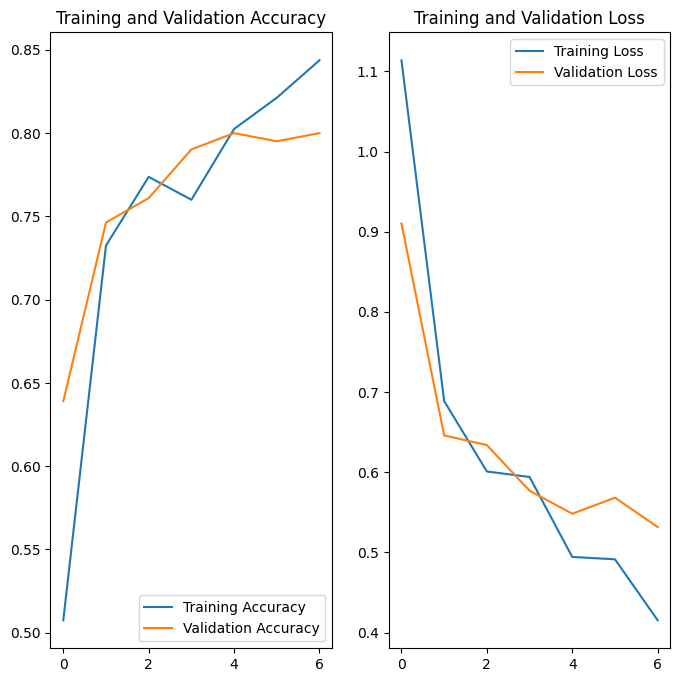

In [9]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(7)

plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

## testing

In [9]:
test_ds = tf.keras.utils.image_dataset_from_directory(
    f'{base_path}/test',
    batch_size=BATCH_SIZE,
)
test_loss, test_acc = model.evaluate(test_ds)
print(f"Test accuracy: {test_acc:.2f}")

Found 146 files belonging to 4 classes.
5/5 ━━━━━━━━━━━━━━━━━━━━ 32s 5s/step - accuracy: 0.6706 - loss: 0.7687
Test accuracy: 0.68


## save model

In [12]:
# Option A: Save as a Keras model (.keras or HDF5)
model.save("../models/BiT/pistachio-BiT.keras")  # or model.save("my_bit_model.h5")

# Option B: Save as a SavedModel (TensorFlow format)
# Define a serving function so input/output signatures are known
# @tf.function(input_signature=[tf.TensorSpec([None, 224, 224, 3], tf.float32)])
# def serve(x):
#     return {"predictions": model(x)}
# tf.saved_model.save(model, "../models/BiT/pistachio-BiT/", signatures={"serving_default": serve})
# tf.saved_model.save(model, "../models/BiT/pistachio-BiT/")

## load model

In [5]:
# If you saved with model.save(...) (.keras or HDF5 format):
model = tf.keras.models.load_model("../models/BiT/pistachio-BiT.keras", custom_objects={"MyBiTModel": MyBiTModel})
# model = tf.keras.models.load_model("../models/BiT/pistachio-BiT.keras")

# If you saved as a SavedModel:
# model = tf.keras.models.load_model("../models/BiT", custom_objects={"MyBiTModel": MyBiTModel})

E0000 00:00:1749293221.568302    4279 cuda_executor.cc:1228] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1749293221.573617    4279 gpu_device.cc:2341] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


In [19]:
import numpy as np
from tensorflow.keras.preprocessing import image
imgpath="/win_d/Programming/University/pistachio-image-classification/pistachio-edited/test/fungus/20230612_1843521_jpg.rf.0298cb77645eb2232178a27caccd79ff.jpg"
# Load and preprocess image
img = image.load_img(imgpath, target_size=(224, 224))  # use your model's input size
img_array = image.img_to_array(img)
img_array = img_array / 255.0  # normalize if your model was trained that way
img_array = np.expand_dims(img_array, axis=0)  # add batch dimension -> (1, 224, 224, 3)

prediction = model.predict(img_array)  # result shape depends on model (e.g., (1, 5) for 5 classes)
predicted_class = np.argmax(prediction, axis=1)[0]
print("Predicted class index:", predicted_class)
labels = ['fungus', 'healthy', 'low-neutrition', 'pecil']
print("Predicted label:", labels[predicted_class])


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 329ms/step
Predicted class index: 0
Predicted label: fungus


## convert to tflite

In [12]:
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
# Optional for quantization
converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS,      # enable TensorFlow Lite ops.
    tf.lite.OpsSet.SELECT_TF_OPS         # enable TensorFlow ops (fallback).
]
tflite_model = converter.convert()

with open("../tflite/pistachio-BiT.tflite", "wb") as f:
    f.write(tflite_model)

AttributeError: 'MyBiTModel' object has no attribute '_get_save_spec'